# House Stage 1 regression

The formula is the model: `run_ols(formula, train_years, eval_years)` fits it with `smf.ols(formula, data=train).fit()` and returns the native statsmodels result as `result.model`. It is the same function as `python -m experiments.house.run` (see `experiments/house/run.py`). Shared data prep, validation, and metrics are in `experiments/house/evaluation.py`, and saved runs in `experiments/house/tracking.py`. Holdout years: `src/house/regression/config.py`. Columns: `src/house/regression/schema.py`.
Build the predictors and targets first: `python data-processing/house/house_features.py` (`modeling.csv`) and `python data-processing/house/house_targets.py` (`targets.csv`).
Imputed targets are never trained on. Evaluation scores `non_imputed` (primary), `imputed`, and `all` from the same predictions. Every left-out row is listed with its reason in `result.excluded`. Nothing is saved unless you ask (`save=True` or `tracking.save_run`).

In [ ]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../../src").resolve()))
sys.path.insert(0, str(Path("../..").resolve()))  # repository root, for experiments.house
import house.regression as hr  # hr.<Tab> lists everything; names are in src/house/regression/__init__.py
from experiments.house import evaluation, tracking
from experiments.house.run import run_ols

In [ ]:
import warnings

with warnings.catch_warnings(action="ignore"):  # loading warns with the same summaries printed below
    predictors = hr.load_predictors()  # data/processed/house/modeling.csv, every year (2006-2026)
    targets = hr.load_targets()        # data/processed/house/targets.csv, every year (2006-2024)
print(hr.validate_schema(predictors).summary())  # .issues lists every affected key

In [ ]:
print(hr.validate_schema(targets, schema=hr.TARGETS_SCHEMA).summary())

In [ ]:
FORMULA = "adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed"
TRAIN_YEARS = [2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020]
EVAL_YEARS = [2022]     # scored against actual targets
PREDICT_YEARS = []      # predicted only, no metrics, e.g. [2026] for a forecast
USE_HOLDOUT = False     # True allows HOLDOUT_YEARS (2024) in training, evaluation, or prediction
REQUIRE_COMPLETE = []   # extra columns a row must have, so runs with different formulas share rows

result = run_ols(
    formula=FORMULA,
    train_years=TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,  # the tables loaded above, instead of reloading per run
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=REQUIRE_COMPLETE,
    name="classic_ols",
    save=False,             # True writes results/house/runs/<run_id>
)
print(tracking.describe(result))  # result.config has the raw values

estimator         ols
formula           adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed
target            adj_margin_2p_norm
name              classic_ols
train_years       2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020
eval_years        2022
predict_years     -
variables         basic_f: [gen_margin_raw, partisan_lean, inc_signed]
require_complete  -
use_holdout       False (HOLDOUT_YEARS: [2024])
train             3087 rows (excluded: imputed_target 393)
eval              435 rows, 435 scored
run_id            (unsaved)
timestamp         2026-10-29T22:45:10
git_commit        53bc539 (dirty)
data_hash         4570f5a8dc10-96211473f2f4
statsmodels       0.15.0


In [ ]:
evaluation.excluded_by_year(result.excluded, max_districts=5)  # every row left out, by year and reason (None lists all)

,role,reason,n,districts
year,,,,
2006,train,imputed_target,55,"AL-05, AL-06, AL-07, AZ-06, CA-07, ... (+50)"
2008,train,imputed_target,56,"AL-01, AL-06, AL-07, AR-01, AR-02, ... (+51)"
2010,train,imputed_target,29,"AL-01, AL-04, AL-06, CA-21, CA-22, ... (+24)"
2012,train,imputed_target,45,"AL-01, AR-03, AZ-07, CA-08, CA-13, ... (+40)"
2014,train,imputed_target,77,"AL-04, AL-05, AL-07, AR-03, AZ-07, ... (+72)"
2016,train,imputed_target,63,"AL-01, AL-04, AL-07, AR-01, AR-03, ... (+58)"
2018,train,imputed_target,41,"AL-07, AZ-07, CA-05, CA-06, CA-08, ... (+36)"
2020,train,imputed_target,27,"AL-05, AL-06, AL-07, AR-01, CA-12, ... (+22)"
total,,,393,


In [ ]:
result.model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     adj_margin_2p_norm   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.907
Method:                 Least Squares   F-statistic:                 1.004e+04
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:45:10   Log-Likelihood:                -11628.
No. Observations:                3087   AIC:                         2.326e+04
Df Residuals:                    3083   BIC:                         2.329e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.4530      0.230     -1.968      0.049      -0.904      -0.002
gen_margin_raw     0.8240      0.031     26.971      0.000       0.764       0.884
partisan_lean      0.8199      0.009     91.227      0.000       0.802       0.837
inc_signed        11.6365      0.281     41.443      0.000      11.086      12.187
==============================================================================
Omnibus:                      224.632   Durbin-Watson:                   1.606
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              913.640
Skew:                           0.244   Prob(JB):                    4.03e-199
Kurtosis:                       5.620   Cond. No.                         43.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
result.metrics  # non_imputed (primary) / imputed (vs. synthetic targets) / all; bias = prediction - actual

,n,mae,rmse,bias
subset,,,,
non_imputed,403,6.674291,9.313316,0.018676
imputed,32,4.712090,5.676114,-2.141144
all,435,6.529945,9.095450,-0.140208


## Prediction diagnostics

The evaluation rows of `result.predictions` (`role == "eval"`, here the 2022 districts), with an actual target. Each row has:

- `prediction`: the model's predicted margin, D positive, in points.
- `actual`: the target, `adj_margin_2p_norm`.
- `is_imputed`: True when the target is a modeled imputation (uncontested and similar races, see `MODELED_IMPUTATION_METHODS`), not an observed result. Imputed targets are never trained on. Jungle and first-round RCV races are observed, so they are non-imputed.
- `residual` = `actual - prediction`, the statsmodels convention (`result.model.resid`).

**Signs:** `residual` and the metrics' `bias` have opposite signs. `bias` is the mean of `prediction - actual`, so positive bias over-predicts the Democratic margin, while a positive residual means the model under-predicted it.

**Reading the two cells below:**

- The residual summary splits observed from imputed rows. The `non_imputed` rows measure accuracy. The `imputed` rows only measure agreement with synthetic targets, which were themselves made from other races.
- The scatter plots actual against predicted. Points on the grey diagonal are exact; points above it are under-predictions (the Democrat did better than predicted).

**Out-of-range predictions:** OLS is unbounded, so a prediction can fall outside the ±100 a margin can take, typically in the safest seats. Predictions are never clipped here, so the backtest scores the raw model. An evaluation or prediction row beyond ±100 raises a warning (in-sample fitted values aren't flagged).

**Clipping at forecast time:** clipping to ±100 belongs to the forecast step, as one visible line. Every actual margin lies within ±100, so clipping can only move a prediction closer to it. The unclipped MAE and RMSE above are therefore a slight upper bound on the clipped forecast's error.

In [ ]:
scored = result.predictions[result.predictions["role"] == "eval"].dropna(subset=["actual"])
scored.groupby("is_imputed")["residual"].describe()  # residual = actual - prediction

,count,mean,std,min,25%,50%,75%,max
is_imputed,,,,,,,,
False,403.0,-0.018676,9.324874,-67.349726,-5.158882,0.457900,5.691521,24.500734
True,32.0,2.141144,5.340897,-8.135856,-1.299707,2.273097,6.442009,11.765936


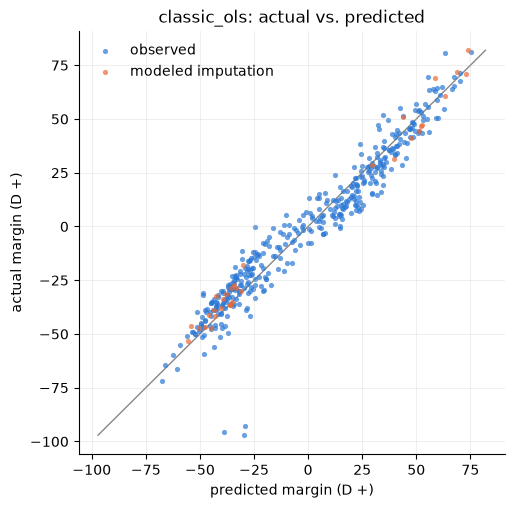

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for imputed, color, label in [(False, "#2a78d6", "observed"), (True, "#eb6834", "modeled imputation")]:
    rows = scored[scored["is_imputed"] == imputed]
    ax.scatter(rows["prediction"], rows["actual"], s=14, color=color, alpha=0.7, linewidths=0, label=label)
lim = [scored[["prediction", "actual"]].min().min(), scored[["prediction", "actual"]].max().max()]
ax.plot(lim, lim, color="#888", lw=1, zorder=0)
ax.set(xlabel="predicted margin (D +)", ylabel="actual margin (D +)", title=f"{result.config['name']}: actual vs. predicted")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Ablations and variants (not saved)

Each variant is just a formula. `require_complete=SHARED_COLUMNS` (every predictor column any formula uses, from `evaluation.shared_columns`) makes every run use the same rows, so `compare` reports `same_train_rows` / `same_eval_rows` as True, and a metric change is a modeling change, not a sample change.

In [ ]:
TARGET = "adj_margin_2p_norm"
VARIANTS = {
    "no_gen_margin_raw": f"{TARGET} ~ partisan_lean + inc_signed",
    "no_partisan_lean": f"{TARGET} ~ gen_margin_raw + inc_signed",
    "no_inc_signed": f"{TARGET} ~ gen_margin_raw + partisan_lean",
    "plus_acs": FORMULA + " + college + hispanic",
    "lean_x_inc": FORMULA + " + partisan_lean:inc_signed",
    "inc_categorical": f"{TARGET} ~ gen_margin_raw + partisan_lean + C(inc_signed)",
}
# every predictor column any formula uses: required on every run, so all runs share the same rows
SHARED_COLUMNS = evaluation.shared_columns(formulas=[FORMULA, *VARIANTS.values()], columns=predictors.columns)
print(SHARED_COLUMNS)

base = run_ols(
    formula=FORMULA,
    train_years=TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=SHARED_COLUMNS,
    name="classic_ols",
    save=False,
)
variants = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=SHARED_COLUMNS,
        name=name,
        save=False,
    )
    for name, formula in VARIANTS.items()
]
tracking.highlight(tracking.compare([base, *variants], full=False))  # full=True for every runs.csv column

['gen_margin_raw', 'partisan_lean', 'inc_signed', 'college', 'hispanic']


In [ ]:
# One row per 2022 district every run predicted: its actual target (adj_margin_2p_norm) and is_imputed, then each
# run's prediction for that district, one column per run (named as in compare above)
tracking.compare_predictions([base, *variants]).head()

,year,state,district,actual,is_imputed,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
0,2022,AK,0,-0.320239,False,-2.968745,1.142944,27.922800,-18.543750,-3.086734,-2.613875,-2.879828
1,2022,AL,1,-37.974972,True,-40.097235,-35.207551,-31.062456,-36.786991,-40.151517,-40.415823,-40.032612
2,2022,AL,2,-40.642745,False,-41.490982,-36.605669,-31.062456,-38.622110,-41.523281,-41.848338,-41.425010
3,2022,AL,3,-47.826514,False,-44.835974,-39.961152,-31.062456,-43.026396,-44.845318,-45.286374,-44.766765
4,2022,AL,4,-72.099149,False,-67.595038,-62.791600,-31.062456,-72.992809,-67.499988,-68.678497,-67.503805


## Saved runs

Save the runs worth keeping: `tracking.save_run(result)` or `run_experiment(..., save=True)`. Each gets a folder in `results/house/runs/` and a row in `results/house/runs.csv`; the CLI saves by default.

In [ ]:
# run_id = tracking.save_run(result)  # or run_ols(..., save=True)

In [ ]:
runs = tracking.load_runs()  # after at least one saved run
runs.sort_values("mae_non_imputed")[["run_id", "formula", "n_train", "mae_non_imputed", "rmse_non_imputed",
                                      "bias_non_imputed", "mae_imputed", "mae_all"]]

FileNotFoundError: [Errno 2] No such file or directory: '/Users/ElijahSong/Documents/Election26/results/house/runs.csv'

In [ ]:
saved = tracking.load_run(runs["run_id"].iloc[-1])  # config, metrics, counts, fit, coefficients, predictions, excluded
saved.coefficients

In [ ]:
tracking.highlight(tracking.compare(runs["run_id"].tail(3).tolist()))